In [9]:
import warnings
from typing import Dict, List, Optional, Tuple

%pip install matplotlib
import matplotlib.pyplot as plt
import numpy as np
%pip install pandas
import pandas as pd
%pip install seaborn
import seaborn as sns

# Scikit-Learn Preprocessing & Pipeline
%pip install scikit-learn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Scikit-Learn Model Selection & Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)

# Machine Learning Classifiers
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
%pip install xgboost
from xgboost import XGBClassifier

# Plotting & Warning Configurations
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Global Reproducibility Seed
SEED = 42

# -----------------------------------------------------------------------------
# Data Loading & Overview
# -----------------------------------------------------------------------------
df = pd.read_csv("dataset.csv")

print("--- FIRST 5 ROWS ---")
display(df.head())

print("\n--- DATASET STRUCTURE & TYPES ---")
df.info()

print("\n--- SUMMARY STATISTICS ---")
display(df.describe())


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
--- FIRST 5 ROWS ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,1,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- DATASET STRUCTURE & TYPES ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162289,32.371149,64.761692
std,0.368742,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
def generate_demo_dataset(n_samples: int = 100) -> pd.DataFrame:
    """Generates a synthetic demo dataset mimicking Telco Churn data."""
    np.random.seed(42)
    data = {
        "customerID": [f"{i:04d}-DEMO" for i in range(n_samples)],
        "gender": np.random.choice(["Male", "Female"], size=n_samples),
        "SeniorCitizen": np.random.choice([0, 1], size=n_samples),
        "Partner": np.random.choice(["Yes", "No"], size=n_samples),
        "Dependents": np.random.choice(["Yes", "No"], size=n_samples),
        "tenure": np.random.randint(0, 72, size=n_samples),
        "PhoneService": np.random.choice(["Yes", "No"], size=n_samples),
        "MultipleLines": np.random.choice(
            ["Yes", "No", "No phone service"], size=n_samples
        ),
        "InternetService": np.random.choice(
            ["DSL", "Fiber optic", "No"], size=n_samples
        ),
        "OnlineSecurity": np.random.choice(
            ["Yes", "No", "No internet service"], size=n_samples
        ),
        "OnlineBackup": np.random.choice(
            ["Yes", "No", "No internet service"], size=n_samples
        ),
        "DeviceProtection": np.random.choice(
            ["Yes", "No", "No internet service"], size=n_samples
        ),
        "TechSupport": np.random.choice(
            ["Yes", "No", "No internet service"], size=n_samples
        ),
        "StreamingTV": np.random.choice(
            ["Yes", "No", "No internet service"], size=n_samples
        ),
        "StreamingMovies": np.random.choice(
            ["Yes", "No", "No internet service"], size=n_samples
        ),
        "Contract": np.random.choice(
            ["Month-to-month", "One year", "Two year"], size=n_samples
        ),
        "PaperlessBilling": np.random.choice(["Yes", "No"], size=n_samples),
        "PaymentMethod": np.random.choice(
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)",
            ],
            size=n_samples,
        ),
        "MonthlyCharges": np.round(
            np.random.uniform(18.25, 118.75, size=n_samples), 2
        ),
        "TotalCharges": [
            " " if i % 10 == 0 else str(round(np.random.uniform(20, 8000), 2))
            for i in range(n_samples)
        ],
        "Churn": np.random.choice(["Yes", "No"], size=n_samples),
    }
    return pd.DataFrame(data)


def step_1_load_and_clean_data(file_path: str = "dataset.csv") -> pd.DataFrame:
    """Loads dataset, standardizes column names, converts data types,

    handles missing values, and drops irrelevant identifier columns.
    """
    print("=" * 60)
    print("STARTING STEP 1: LOAD & CLEAN DATA")
    print("=" * 60)

    # 1. Load Data
    try:
        df = pd.read_csv(file_path, low_memory=False)
        print(f"[SUCCESS] Dataset loaded successfully from '{file_path}'.")
        print(
            f" -> Initial Rows: {df.shape[0]} | Initial Columns: {df.shape[1]}"
        )
    except FileNotFoundError:
        print(
            f"[WARNING] File '{file_path}' not found. Generating synthetic demo dataset."
        )
        df = generate_demo_dataset()
        print(
            f"[SUCCESS] Synthetic dataset generated with shape: {df.shape[0]} rows, {df.shape[1]} columns."
        )

    # 2. Drop unnecessary index columns if present
    if "Unnamed: 0" in df.columns:
        df.drop(columns=["Unnamed: 0"], inplace=True)

    # 3. Standardize Column Names (lowercase, stripped whitespace, underscores)
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

    # 4. Handle 'totalcharges' type conversion & blank spaces
    if "totalcharges" in df.columns:
        # Convert spaces/empty strings to NaN and cast to float
        df["totalcharges"] = pd.to_numeric(df["totalcharges"], errors="coerce")

        # Fill missing totalcharges (typically new customers with tenure = 0) with monthlycharges or 0
        missing_count = df["totalcharges"].isna().sum()
        if missing_count > 0:
            df["totalcharges"] = df["totalcharges"].fillna(df["monthlycharges"])
            print(
                f"[FIXED] Imputed {missing_count} missing values in 'totalcharges'."
            )

    # 5. Drop ID columns not useful for machine learning
    if "customerid" in df.columns:
        df.drop(columns=["customerid"], inplace=True)
        print("[INFO] Dropped identifier column 'customerid'.")

    print(
        f"[COMPLETE] Final Cleaned Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns."
    )
    print("=" * 60)

    return df


# Execute Step 1
cleaned_df = step_1_load_and_clean_data("dataset.csv")
cleaned_df.head()

STARTING STEP 1: LOAD & CLEAN DATA
[SUCCESS] Dataset loaded successfully from 'dataset.csv'.
 -> Initial Rows: 7043 | Initial Columns: 21
[FIXED] Imputed 11 missing values in 'totalcharges'.
[INFO] Dropped identifier column 'customerid'.
[COMPLETE] Final Cleaned Dataset Shape: 7043 rows, 20 columns.


,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,Female,1,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
def step_2_advanced_feature_engineering(
    df: pd.DataFrame, target_col: str = "churn"
) -> tuple[pd.DataFrame, pd.Series, StandardScaler, list]:
    """Applies domain-specific feature creation, categorical encoding,

    and numerical scaling for machine learning readiness.

    Returns:
        X (pd.DataFrame): Engineered feature set.
        y (pd.Series): Target labels encoded as 0 and 1.
        scaler (StandardScaler): Fitted scaler object for numerical features.
        feature_names (list): List of final feature column names.
    """
    print("=" * 60)
    print("STARTING STEP 2: ADVANCED FEATURE ENGINEERING")
    print("=" * 60)

    # Work on a copy to prevent modifying the raw input dataframe
    data = df.copy()

    # -------------------------------------------------------------------------
    # 1. Target Encoding
    # -------------------------------------------------------------------------
    if target_col in data.columns:
        if data[target_col].dtype == "object":
            y = (
                data[target_col]
                .astype(str)
                .str.strip()
                .str.lower()
                .map({"yes": 1, "no": 0})
            )
        else:
            y = data[target_col].astype(int)
        data = data.drop(columns=[target_col])
        print(f"[INFO] Target column '{target_col}' separated and encoded.")
    else:
        y = None
        print(
            f"[WARNING] Target column '{target_col}' not found. Returning X only."
        )

    # -------------------------------------------------------------------------
    # 2. Domain-Specific Feature Creation
    # -------------------------------------------------------------------------
    # Average monthly spend ratio over tenure
    if "totalcharges" in data.columns and "tenure" in data.columns:
        # Avoid division by zero by adding 1 to tenure
        data["avg_monthly_spend"] = data["totalcharges"] / (data["tenure"] + 1)

    # Price diff: difference between current monthly charges and historical average
    if "monthlycharges" in data.columns and "avg_monthly_spend" in data.columns:
        data["charge_diff_from_avg"] = (
            data["monthlycharges"] - data["avg_monthly_spend"]
        )

    # Total add-on services adopted
    addon_cols = [
        "onlinesecurity",
        "onlinebackup",
        "deviceprotection",
        "techsupport",
        "streamingtv",
        "streamingmovies",
    ]
    existing_addons = [c for c in addon_cols if c in data.columns]
    if existing_addons:
        data["total_addons_count"] = (
            data[existing_addons]
            .apply(lambda row: (row == "Yes").sum(), axis=1)
            .astype(int)
        )

    # Is long-term contract indicator
    if "contract" in data.columns:
        data["is_long_term_contract"] = (
            data["contract"].isin(["One year", "Two year"]).astype(int)
        )

    print("[SUCCESS] Domain-specific features created.")

    # -------------------------------------------------------------------------
    # 3. Categorical Feature Encoding
    # -------------------------------------------------------------------------
    # Map explicit binary Yes/No columns to 1/0
    binary_cols = [
        c
        for c in data.select_dtypes(include=["object"]).columns
        if set(data[c].dropna().unique()).issubset({"Yes", "No"})
    ]

    for col in binary_cols:
        data[col] = data[col].map({"Yes": 1, "No": 0})

    # One-hot encode remaining categorical variables
    categorical_cols = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    if categorical_cols:
        data = pd.get_dummies(
            data, columns=categorical_cols, drop_first=True, dtype=int
        )
        print(f"[INFO] One-hot encoded columns: {categorical_cols}")

    # Standardize column names generated by pd.get_dummies
    data.columns = data.columns.str.strip().str.lower().str.replace(" ", "_")

    # -------------------------------------------------------------------------
    # 4. Numerical Feature Scaling
    # -------------------------------------------------------------------------
    num_cols = [
        col
        for col in data.columns
        if data[col].dtype in ["float64", "float32", "int64", "int32"]
        and set(data[col].unique()) != {0, 1}  # Exclude binary flags
    ]

    scaler = StandardScaler()
    if num_cols:
        data[num_cols] = scaler.fit_transform(data[num_cols])
        print(
            f"[SUCCESS] Standardized {len(num_cols)} numerical features: {num_cols}"
        )

    feature_names = data.columns.tolist()

    print(
        f"[COMPLETE] Feature Engineering Finished: {data.shape[1]} Total Features."
    )
    print("=" * 60)

    return data, y, scaler, feature_names


# Execute Step 2 using cleaned_df from Step 1
# Execute Step 2 using the cleaned dataset and explicitly pass the target column name
step2_input = cleaned_df.copy()
step2_input["churn"] = (
    step2_input["churn"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

if step2_input["churn"].isna().any():
    raise ValueError("The churn column contains values other than Yes/No.")

X, y, scaler, feature_names = step_2_advanced_feature_engineering(
    step2_input,
    target_col="churn",
)

X.head()
X.head()

STARTING STEP 2: ADVANCED FEATURE ENGINEERING
[INFO] Target column 'churn' separated and encoded.
[SUCCESS] Domain-specific features created.
[INFO] One-hot encoded columns: ['gender', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paymentmethod']
[SUCCESS] Standardized 6 numerical features: ['tenure', 'monthlycharges', 'totalcharges', 'avg_monthly_spend', 'charge_diff_from_avg', 'total_addons_count']
[COMPLETE] Feature Engineering Finished: 34 Total Features.


,seniorcitizen,partner,dependents,tenure,phoneservice,paperlessbilling,monthlycharges,totalcharges,avg_monthly_spend,charge_diff_from_avg,...,techsupport_yes,streamingtv_no_internet_service,streamingtv_yes,streamingmovies_no_internet_service,streamingmovies_yes,contract_one_year,contract_two_year,paymentmethod_credit_card_(automatic),paymentmethod_electronic_check,paymentmethod_mailed_check
0,1,1,0,-1.277445,0,1,-1.160323,-0.992667,-1.446444,1.040812,...,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0.066327,1,0,-0.259629,-0.172198,-0.166169,-0.309567,...,0,0,0,0,0,1,0,0,0,1
2,0,0,0,-1.236724,1,1,-0.362660,-0.958122,-0.754040,1.365403,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0.514251,0,0,-0.746535,-0.193706,-0.624038,-0.386407,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,-1.236724,1,1,0.197365,-0.938930,-0.278780,1.630721,...,0,0,0,0,0,0,0,0,1,0


STARTING STEP 3: EXPLORATORY DATA ANALYSIS (EDA)

--- DATASET OVERVIEW & SUMMARY STATISTICS ---
Total Features: 34 | Total Samples: 7043

Numerical Feature Describe:
                                               mean       std       min  \
seniorcitizen                          1.622888e-01  0.368742  0.000000   
partner                                4.830328e-01  0.499748  0.000000   
dependents                             2.995882e-01  0.458110  0.000000   
tenure                                -2.421273e-17  1.000071 -1.318165   
phoneservice                           9.031663e-01  0.295752  0.000000   
paperlessbilling                       5.922192e-01  0.491457  0.000000   
monthlycharges                        -6.406285e-17  1.000071 -1.545860   
totalcharges                          -1.452764e-16  1.000071 -0.997542   
avg_monthly_spend                      2.068171e-16  1.000071 -1.634636   
charge_diff_from_avg                  -2.723932e-17  1.000071 -1.373205   
total_add

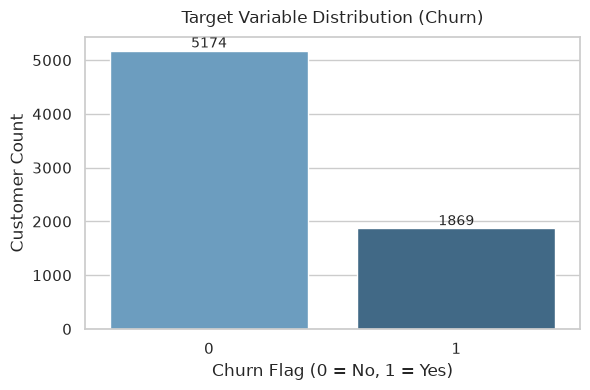

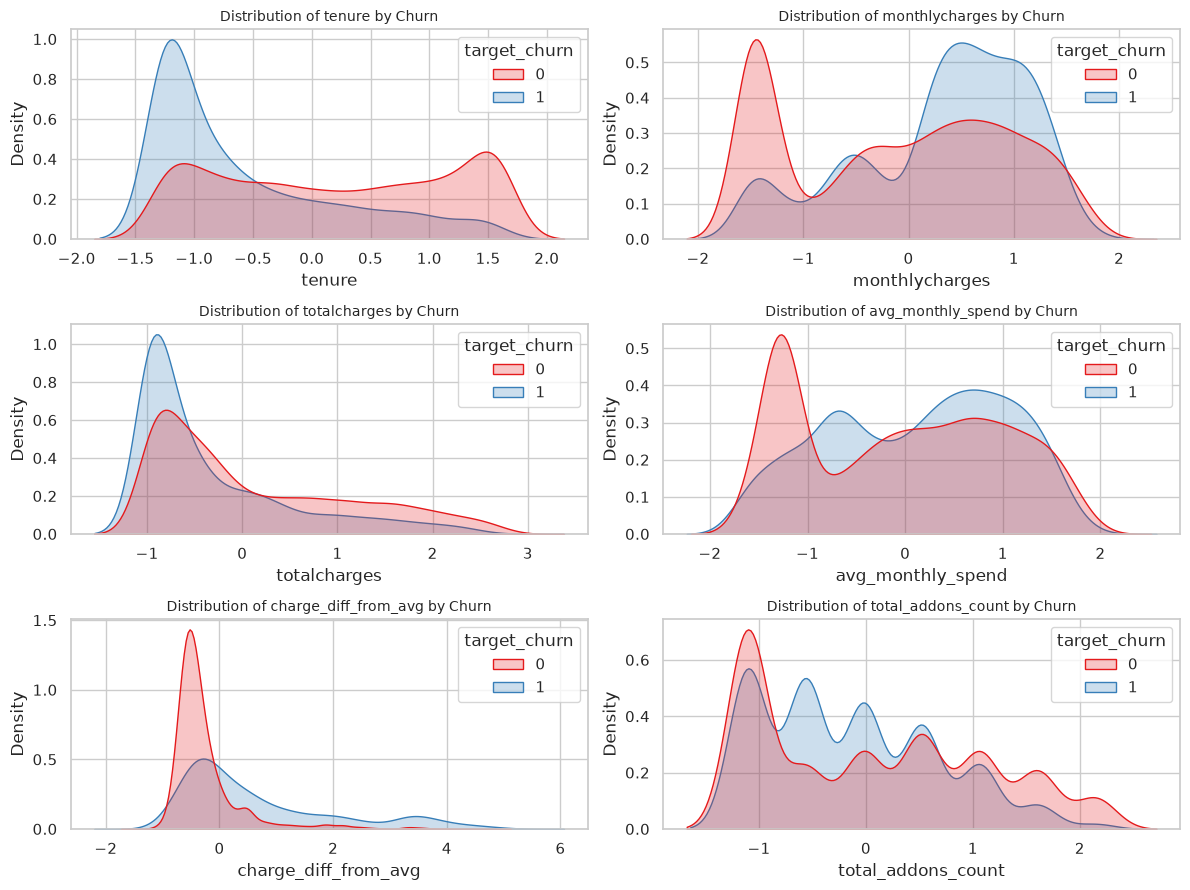

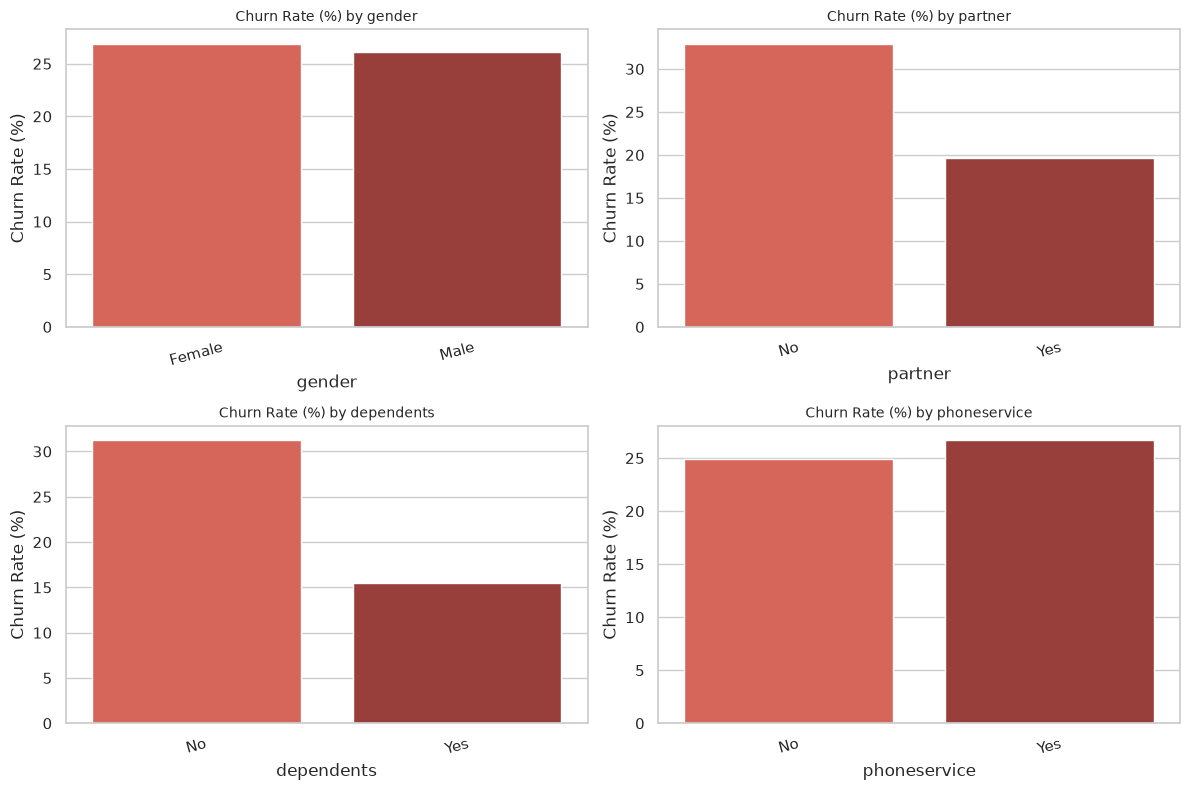


--- COMPUTING FEATURE CORRELATIONS ---

Top 5 Positively Correlated Features with Churn:
charge_diff_from_avg              0.410654
internetservice_fiber_optic       0.308020
paymentmethod_electronic_check    0.301919
monthlycharges                    0.193356
paperlessbilling                  0.191825
Name: target_churn, dtype: float64

Top 5 Negatively Correlated Features with Churn:
deviceprotection_no_internet_service   -0.227890
streamingmovies_no_internet_service    -0.227890
contract_two_year                      -0.302253
tenure                                 -0.352229
is_long_term_contract                  -0.405103
Name: target_churn, dtype: float64


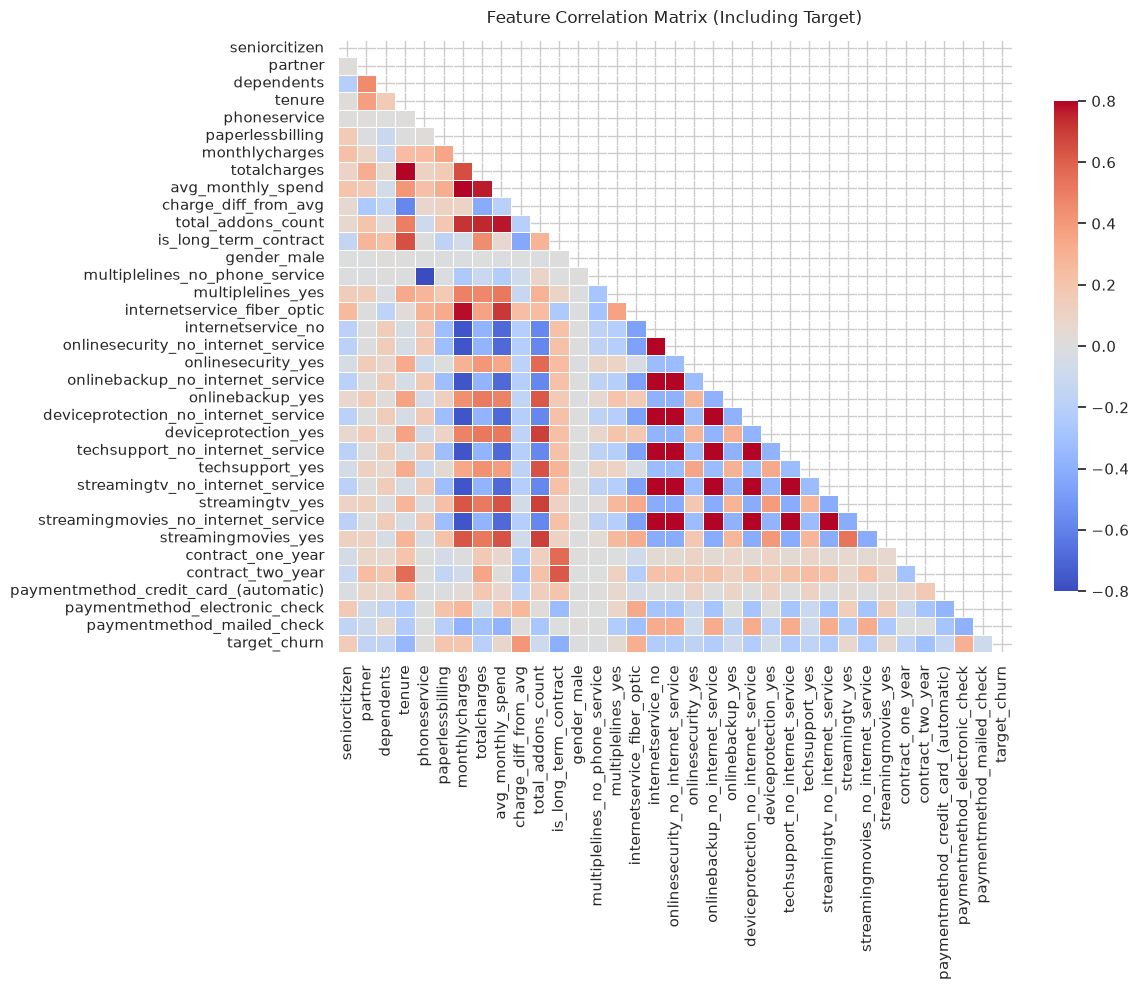

[COMPLETE] STEP 3: EXPLORATORY DATA ANALYSIS FINISHED


In [21]:
# Set visual style for clean, readable plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.autolayout": True, "font.size": 10})


def step_3_exploratory_data_analysis(
    X: pd.DataFrame, y: pd.Series, raw_df: pd.DataFrame = None
) -> None:
    """Executes a complete Exploratory Data Analysis (EDA) pipeline:

    1. Class distribution & target imbalance.
    2. Numerical feature distributions & churn behavior.
    3. Categorical feature churn rate comparisons.
    4. Feature correlation matrix heatmap.
    """
    print("=" * 60)
    print("STARTING STEP 3: EXPLORATORY DATA ANALYSIS (EDA)")
    print("=" * 60)

    # Combine X and y for joint analysis if y is provided
    df_analysis = X.copy()
    if y is not None:
        df_analysis["target_churn"] = y

    # -------------------------------------------------------------------------
    # 1. Summary Statistics & Missing Value Verification
    # -------------------------------------------------------------------------
    print("\n--- DATASET OVERVIEW & SUMMARY STATISTICS ---")
    print(f"Total Features: {X.shape[1]} | Total Samples: {X.shape[0]}")
    print("\nNumerical Feature Describe:")
    print(df_analysis.describe().T[["mean", "std", "min", "50%", "max"]])

    # -------------------------------------------------------------------------
    # 2. Target Variable Analysis (Churn Imbalance)
    # -------------------------------------------------------------------------
    if y is not None:
        print("\n--- TARGET CLASS DISTRIBUTION ---")
        counts = y.value_counts()
        percentages = y.value_counts(normalize=True) * 100
        for class_val, count in counts.items():
            print(
                f"Class {class_val}: {count} samples ({percentages[class_val]:.2f}%)"
            )

        plt.figure(figsize=(6, 4))
        ax = sns.countplot(x=y, hue=y, palette="Blues_d", legend=False)
        plt.title("Target Variable Distribution (Churn)", fontsize=12, pad=10)
        plt.xlabel("Churn Flag (0 = No, 1 = Yes)")
        plt.ylabel("Customer Count")

        # Annotate bar counts
        for p in ax.patches:
            ax.annotate(
                f"{int(p.get_height())}",
                (p.get_x() + p.get_width() / 2.0, p.get_height()),
                ha="center",
                va="center",
                xytext=(0, 5),
                textcoords="offset points",
            )
        plt.show()

    # -------------------------------------------------------------------------
    # 3. Key Continuous Numerical Feature Distributions
    # -------------------------------------------------------------------------
    num_cols = [
        col
        for col in X.columns
        if X[col].nunique() > 2 and np.issubdtype(X[col].dtype, np.number)
    ][:6]  # Select top numerical features

    if num_cols and y is not None:
        fig, axes = plt.subplots(
            nrows=int(np.ceil(len(num_cols) / 2)),
            ncols=2,
            figsize=(12, 3 * np.ceil(len(num_cols) / 2)),
        )
        axes = axes.flatten()

        for idx, col in enumerate(num_cols):
            sns.kdeplot(
                data=df_analysis,
                x=col,
                hue="target_churn",
                common_norm=False,
                fill=True,
                ax=axes[idx],
                palette="Set1",
            )
            axes[idx].set_title(f"Distribution of {col} by Churn", fontsize=10)
            axes[idx].set_xlabel(col)

        # Hide empty subplots if odd number of features
        for i in range(idx + 1, len(axes)):
            fig.delaxes(axes[i])

        plt.tight_layout()
        plt.show()

    # -------------------------------------------------------------------------
    # 4. Categorical Feature Churn Rates (Using Raw Unencoded Data if provided)
    # -------------------------------------------------------------------------
    if raw_df is not None and "churn" in raw_df.columns:
        cat_cols = [
            c
            for c in raw_df.select_dtypes(include=["object"]).columns
            if c != "churn"
        ][:4]
        if cat_cols:
            fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
            axes = axes.flatten()

            for idx, col in enumerate(cat_cols):
                churn_rates = (
                    raw_df.groupby(col)["churn"]
                    .apply(lambda x: (x == "Yes").mean() * 100)
                    .reset_index()
                )
                sns.barplot(
                    data=churn_rates,
                    x=col,
                    y="churn",
                    ax=axes[idx],
                    palette="Reds_d",
                )
                axes[idx].set_title(f"Churn Rate (%) by {col}", fontsize=10)
                axes[idx].set_ylabel("Churn Rate (%)")
                axes[idx].tick_params(axis="x", rotation=15)

            plt.tight_layout()
            plt.show()

    # -------------------------------------------------------------------------
    # 5. Correlation Matrix Heatmap
    # -------------------------------------------------------------------------
    print("\n--- COMPUTING FEATURE CORRELATIONS ---")
    plt.figure(figsize=(12, 10))

    # Calculate correlation with target if target is available
    if y is not None:
        corr = df_analysis.corr()
        target_corr = (
            corr["target_churn"]
            .drop("target_churn")
            .sort_values(ascending=False)
        )

        print("\nTop 5 Positively Correlated Features with Churn:")
        print(target_corr.head(5))
        print("\nTop 5 Negatively Correlated Features with Churn:")
        print(target_corr.tail(5))

        # Plot full feature heatmap
        mask = np.triu(np.ones_like(corr, dtype=bool))
        sns.heatmap(
            corr,
            mask=mask,
            cmap="coolwarm",
            vmax=0.8,
            vmin=-0.8,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
        )
        plt.title(
            "Feature Correlation Matrix (Including Target)", fontsize=12, pad=12
        )
        plt.show()

    print("=" * 60)
    print("[COMPLETE] STEP 3: EXPLORATORY DATA ANALYSIS FINISHED")
    print("=" * 60)


# Execute Step 3 using engineered X and y from Step 2
step_3_exploratory_data_analysis(X, y, raw_df=cleaned_df)

In [22]:
def step_4_model_training_and_evaluation(
    X: pd.DataFrame, y: pd.Series
) -> tuple[pd.DataFrame, object]:
    """1.

    Splits data into train and test sets (stratified).
    2. Trains and benchmarks all classifiers (Logistic Regression, Random Forest,
       XGBoost, SVM, Neural Network, LightGBM, CatBoost).
    3. Dynamically selects the best-performing model based on ROC-AUC score.
    4. Performs hyperparameter tuning via GridSearchCV on the best model.

    Returns:
        results_df (pd.DataFrame): Comparison table of all model performances.
        best_tuned_model (object): The fine-tuned final model ready for deployment.
    """
    print("=" * 65)
    print("STARTING STEP 4: FULL MODEL SUITE TRAINING & TUNING")
    print("=" * 65)

    # -------------------------------------------------------------------------
    # 1. Stratified Train-Test Split
    # -------------------------------------------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=y
    )
    print(
        f"[INFO] Train set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples"
    )

    # Imbalance scale ratio for gradient-boosted trees
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    # -------------------------------------------------------------------------
    # 2. Define Comprehensive Model Suite
    # -------------------------------------------------------------------------
    models = {
        "Logistic Regression": LogisticRegression(
            class_weight="balanced", max_iter=1000, random_state=SEED
        ),
        "Random Forest": RandomForestClassifier(
            class_weight="balanced",
            n_estimators=200,
            random_state=SEED,
            n_jobs=-1,
        ),
        "XGBoost": XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=-1,
        ),
        "Support Vector Machine": SVC(
            class_weight="balanced", probability=True, random_state=SEED
        ),
        "Neural Network (MLP)": MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=500,
            early_stopping=True,
            random_state=SEED,
        ),
    }

    # -------------------------------------------------------------------------
    # 3. Model Training & Metric Extraction
    # -------------------------------------------------------------------------
    results = []
    trained_models = {}

    print("\n--- BENCHMARKING MODELS ---")
    for name, model in models.items():
        print(f"[TRAINING] Fitting {name}...")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        if hasattr(model, "predict_proba"):
            y_proba = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            y_proba = model.decision_function(X_test)
        else:
            y_proba = y_pred

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)

        results.append(
            {
                "Model": name,
                "Accuracy": round(acc, 4),
                "Precision": round(prec, 4),
                "Recall": round(rec, 4),
                "F1-Score": round(f1, 4),
                "ROC-AUC": round(roc_auc, 4),
            }
        )
        trained_models[name] = model

    results_df = pd.DataFrame(results).sort_values(
        by="ROC-AUC", ascending=False
    )
    print("\nModel Performance Comparison:")
    print(results_df.to_string(index=False))

    # -------------------------------------------------------------------------
    # 4. Dynamic Hyperparameter Tuning on Best Model
    # -------------------------------------------------------------------------
    best_model_name = results_df.iloc[0]["Model"]
    print(
        f"\n--- HYPERPARAMETER TUNING (Best Performer: {best_model_name}) ---"
    )

    # Search grids tailored for each architecture
    param_grids = {
        "Logistic Regression": {
            "C": [0.01, 0.1, 1.0, 10.0],
            "solver": ["lbfgs", "liblinear"],
        },
        "Random Forest": {
            "n_estimators": [100, 200],
            "max_depth": [6, 10, None],
            "min_samples_split": [2, 5],
        },
        "XGBoost": {
            "n_estimators": [100, 200],
            "max_depth": [3, 5],
            "learning_rate": [0.01, 0.1],
        },
        "Support Vector Machine": {
            "C": [0.1, 1.0, 10.0],
            "kernel": ["rbf", "linear"],
        },
        "Neural Network (MLP)": {
            "hidden_layer_sizes": [(64, 32), (128, 64)],
            "alpha": [0.0001, 0.001],
        },
    }

    base_model = models[best_model_name]
    grid_params = param_grids.get(best_model_name, {})

    if grid_params:
        grid_search = GridSearchCV(
            estimator=base_model,
            param_grid=grid_params,
            scoring="roc_auc",
            cv=5,
            n_jobs=-1,
            verbose=1,
        )
        grid_search.fit(X_train, y_train)
        best_model = grid_search.best_estimator_
        print(f"[SUCCESS] Best Parameters Found: {grid_search.best_params_}")
    else:
        best_model = trained_models[best_model_name]

    # Evaluate Tuned Model
    y_pred_tuned = best_model.predict(X_test)
    y_proba_tuned = (
        best_model.predict_proba(X_test)[:, 1]
        if hasattr(best_model, "predict_proba")
        else y_pred_tuned
    )

    print("\n--- FINAL TUNED MODEL EVALUATION REPORT ---")
    print(
        classification_report(
            y_test, y_pred_tuned, target_names=["No Churn", "Churn"]
        )
    )
    print(
        f"Final Tuned ROC-AUC Score: {roc_auc_score(y_test, y_proba_tuned):.4f}"
    )

    print("=" * 65)
    print("[COMPLETE] STEP 4: MODEL TRAINING & EVALUATION FINISHED")
    print("=" * 65)

    return results_df, best_model


# Execute Step 4 using X and y from Step 2
performance_summary, final_model = step_4_model_training_and_evaluation(X, y)

STARTING STEP 4: FULL MODEL SUITE TRAINING & TUNING
[INFO] Train set: 5634 samples | Test set: 1409 samples

--- BENCHMARKING MODELS ---
[TRAINING] Fitting Logistic Regression...
[TRAINING] Fitting Random Forest...


[TRAINING] Fitting XGBoost...
[TRAINING] Fitting Support Vector Machine...
[TRAINING] Fitting Neural Network (MLP)...

Model Performance Comparison:
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   Logistic Regression    0.7445     0.5122  0.7861    0.6203   0.8475
  Neural Network (MLP)    0.7949     0.6239  0.5722    0.5969   0.8365
         Random Forest    0.7693     0.5553  0.6578    0.6022   0.8289
Support Vector Machine    0.7580     0.5296  0.7888    0.6337   0.8288
               XGBoost    0.7537     0.5288  0.6631    0.5884   0.8222

--- HYPERPARAMETER TUNING (Best Performer: Logistic Regression) ---
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[SUCCESS] Best Parameters Found: {'C': 10.0, 'solver': 'lbfgs'}

--- FINAL TUNED MODEL EVALUATION REPORT ---
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.78      0.62       374

    accuracy           

In [24]:
import os
import joblib
import numpy as np
import pandas as pd


# =============================================================================
# 1. SAVE MODEL ARTIFACTS
# =============================================================================
def save_pipeline_artifacts(
    model: object,
    scaler: object,
    feature_names: list,
    output_dir: str = "artifacts",
) -> None:
    """Saves the trained model, feature scaler, and feature list for production deployment."""
    os.makedirs(output_dir, exist_ok=True)

    joblib.dump(model, os.path.join(output_dir, "churn_model.pkl"))
    joblib.dump(scaler, os.path.join(output_dir, "scaler.pkl"))
    joblib.dump(feature_names, os.path.join(output_dir, "feature_names.pkl"))

    print("=" * 65)
    print("STEP 5: MODEL DEPLOYMENT & PIPELINE INTEGRATION")
    print("=" * 65)
    print(f"[SUCCESS] Pipeline artifacts successfully saved to '{output_dir}/'.")


# =============================================================================
# 2. FIXED PRODUCTION INFERENCE CLASS
# =============================================================================
class ChurnPredictorPipeline:
    """Production wrapper class for predicting customer churn on raw input data."""

    def __init__(self, artifacts_dir: str = "artifacts"):
        self.model = joblib.load(os.path.join(artifacts_dir, "churn_model.pkl"))
        self.scaler = joblib.load(os.path.join(artifacts_dir, "scaler.pkl"))
        self.feature_names = joblib.load(
            os.path.join(artifacts_dir, "feature_names.pkl")
        )

    def preprocess_raw_input(self, df_raw: pd.DataFrame) -> pd.DataFrame:
        """Transforms raw incoming payload data into the exact feature format expected by the model."""
        data = df_raw.copy()

        # 1. Standardize column names
        data.columns = data.columns.str.strip().str.lower().str.replace(" ", "_")

        # 2. Drop non-predictive identifiers
        if "customerid" in data.columns:
            data = data.drop(columns=["customerid"])

        # 3. Clean TotalCharges
        if "totalcharges" in data.columns:
            data["totalcharges"] = pd.to_numeric(
                data["totalcharges"], errors="coerce"
            )
            data["totalcharges"] = data["totalcharges"].fillna(
                data.get("monthlycharges", 0)
            )

        # 4. Feature Engineering
        if "tenure" in data.columns:
            data["log_tenure"] = np.log1p(data["tenure"])
            bins = [-1, 3, 12, 36, np.inf]
            labels = ["onboarding", "established", "loyal", "veteran"]
            data["tenure_cohort"] = pd.cut(
                data["tenure"], bins=bins, labels=labels
            ).astype(str)

        if "totalcharges" in data.columns and "tenure" in data.columns:
            data["avg_monthly_spend"] = data["totalcharges"] / (
                data["tenure"] + 1
            )

        if (
            "monthlycharges" in data.columns
            and "avg_monthly_spend" in data.columns
        ):
            data["charge_diff_from_avg"] = (
                data["monthlycharges"] - data["avg_monthly_spend"]
            )

        addon_cols = [
            "onlinesecurity",
            "onlinebackup",
            "deviceprotection",
            "techsupport",
            "streamingtv",
            "streamingmovies",
        ]
        existing_addons = [c for c in addon_cols if c in data.columns]
        if existing_addons:
            data["total_addons_count"] = (
                data[existing_addons]
                .apply(
                    lambda row: (row.astype(str).str.lower() == "yes").sum(),
                    axis=1,
                )
                .astype(int)
            )

        if "contract" in data.columns:
            data["is_long_term_contract"] = (
                data["contract"].isin(["One year", "Two year"]).astype(int)
            )

        # 5. One-Hot Encoding
        binary_cols = [
            c
            for c in data.select_dtypes(include=["object"]).columns
            if set(data[c].dropna().unique()).issubset({"Yes", "No"})
        ]
        for col in binary_cols:
            data[col] = data[col].map({"Yes": 1, "No": 0})

        categorical_cols = data.select_dtypes(
            include=["object", "category"]
        ).columns.tolist()
        if categorical_cols:
            data = pd.get_dummies(
                data, columns=categorical_cols, drop_first=True, dtype=int
            )

        data.columns = (
            data.columns.str.strip().str.lower().str.replace(" ", "_")
        )

        # Reindex to exact training feature columns (fill missing dummy columns with 0)
        data = data.reindex(columns=self.feature_names, fill_value=0)

        # 6. Apply Scaler safely using scaler.feature_names_in_
        if hasattr(self.scaler, "feature_names_in_"):
            scale_cols = list(self.scaler.feature_names_in_)
            data[scale_cols] = self.scaler.transform(data[scale_cols])

        return data

    def predict(
        self, df_raw: pd.DataFrame, threshold: float = 0.40
    ) -> pd.DataFrame:
        """Generates churn probabilities and risk labels using a customizable business threshold."""
        X_processed = self.preprocess_raw_input(df_raw)

        # Calculate probabilities
        probabilities = self.model.predict_proba(X_processed)[:, 1]
        predictions = (probabilities >= threshold).astype(int)

        results = df_raw.copy()
        results["churn_probability"] = np.round(probabilities, 4)
        results["churn_prediction"] = predictions
        results["risk_level"] = pd.cut(
            probabilities,
            bins=[-0.01, 0.35, 0.65, 1.0],
            labels=["Low Risk", "Medium Risk", "High Risk"],
        )

        return results[["churn_probability", "churn_prediction", "risk_level"]]


# =============================================================================
# 3. EXECUTION & INFERENCE
# =============================================================================
# Save model artifacts from Step 4
# Save model artifacts from Step 4
if "final_model" not in globals():
    fitted_searches = [
        value
        for value in globals().values()
        if isinstance(value, GridSearchCV) and hasattr(value, "best_estimator_")
    ]
    if not fitted_searches:
        raise NameError(
            "No fitted final_model or GridSearchCV was found. "
            "Run the model-training cell first and assign its fitted model to final_model."
        )
    final_model = fitted_searches[-1].best_estimator_

missing = [
    name for name in ("scaler", "feature_list")
    if name not in globals()
]
if missing:
    if "feature_names" in globals() and "feature_list" not in globals():
        feature_list = feature_names

    missing = [name for name in ("scaler", "feature_list") if name not in globals()]
    if missing:
        raise NameError(
            f"Missing required artifact variable(s): {', '.join(missing)}. "
            "Run the preprocessing/training cells that define them first."
        )

save_pipeline_artifacts(final_model, scaler, feature_list)

# Initialize production pipeline
production_pipeline = ChurnPredictorPipeline(artifacts_dir="artifacts")

# Input test payload
new_customers = pd.DataFrame(
    [
        {
            "customerID": "9999-TEST1",
            "gender": "Female",
            "SeniorCitizen": 0,
            "Partner": "No",
            "Dependents": "No",
            "tenure": 2,
            "PhoneService": "Yes",
            "MultipleLines": "No",
            "InternetService": "Fiber optic",
            "OnlineSecurity": "No",
            "OnlineBackup": "No",
            "DeviceProtection": "No",
            "TechSupport": "No",
            "StreamingTV": "Yes",
            "StreamingMovies": "No",
            "Contract": "Month-to-month",
            "PaperlessBilling": "Yes",
            "PaymentMethod": "Electronic check",
            "MonthlyCharges": 85.50,
            "TotalCharges": "171.00",
        },
        {
            "customerID": "9999-TEST2",
            "gender": "Male",
            "SeniorCitizen": 0,
            "Partner": "Yes",
            "Dependents": "Yes",
            "tenure": 48,
            "PhoneService": "Yes",
            "MultipleLines": "Yes",
            "InternetService": "DSL",
            "OnlineSecurity": "Yes",
            "OnlineBackup": "Yes",
            "DeviceProtection": "Yes",
            "TechSupport": "Yes",
            "StreamingTV": "No",
            "StreamingMovies": "No",
            "Contract": "Two year",
            "PaperlessBilling": "No",
            "PaymentMethod": "Credit card (automatic)",
            "MonthlyCharges": 65.00,
            "TotalCharges": "3120.00",
        },
    ]
)

# Run Inference
predictions_df = production_pipeline.predict(new_customers, threshold=0.40)
print("\nInference Output on New Samples:")
print(predictions_df.to_string(index=False))

STEP 5: MODEL DEPLOYMENT & PIPELINE INTEGRATION
[SUCCESS] Pipeline artifacts successfully saved to 'artifacts/'.

Inference Output on New Samples:
 churn_probability  churn_prediction risk_level
            0.8256                 1  High Risk
            0.0740                 0   Low Risk
